# 07. Monotonic constraints and calibration

## Monotonic constraints
A boosted model can learn that, in some narrow range, *more* sewage means a *higher* chance of good status:
noise fitted as signal, or a confounder. For a decision tool that is unacceptable. A monotone-decreasing
constraint on feature $j$ forces $f(x)$ to be non-increasing in $x_j$ with everything else held fixed.

How it is enforced: when a split on $x_j$ is considered, it is only allowed if the left child's value is
≥ the right child's (for a decreasing constraint), and bounds are passed down so that no later split in
either subtree can cross the other's values.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))
# a small, readable working set used throughout
F = ["up_stw_dwf_m3d_per_km2", "up_spill_hours_per_km2", "up_lc_urban", "up_lc_arable",
     "up_lc_improved_grass", "up_lc_seminatural", "up_area_km2", "local_n_private_sewage"]
d = t[t.phos_good.notna()].reset_index(drop=True)
X, y = d[F].to_numpy(float), d.phos_good.to_numpy(int)
groups = d.management_catchment.to_numpy()
print(X.shape, "share with good phosphate:", y.mean().round(3))

(3706, 8) share with good phosphate: 0.484


{'up_stw_dwf_m3d_per_km2': -1, 'up_spill_hours_per_km2': -1, 'up_lc_urban': -1, 'up_lc_arable': 0, 'up_lc_improved_grass': 0, 'up_lc_seminatural': 0, 'up_area_km2': 0, 'local_n_private_sewage': -1}


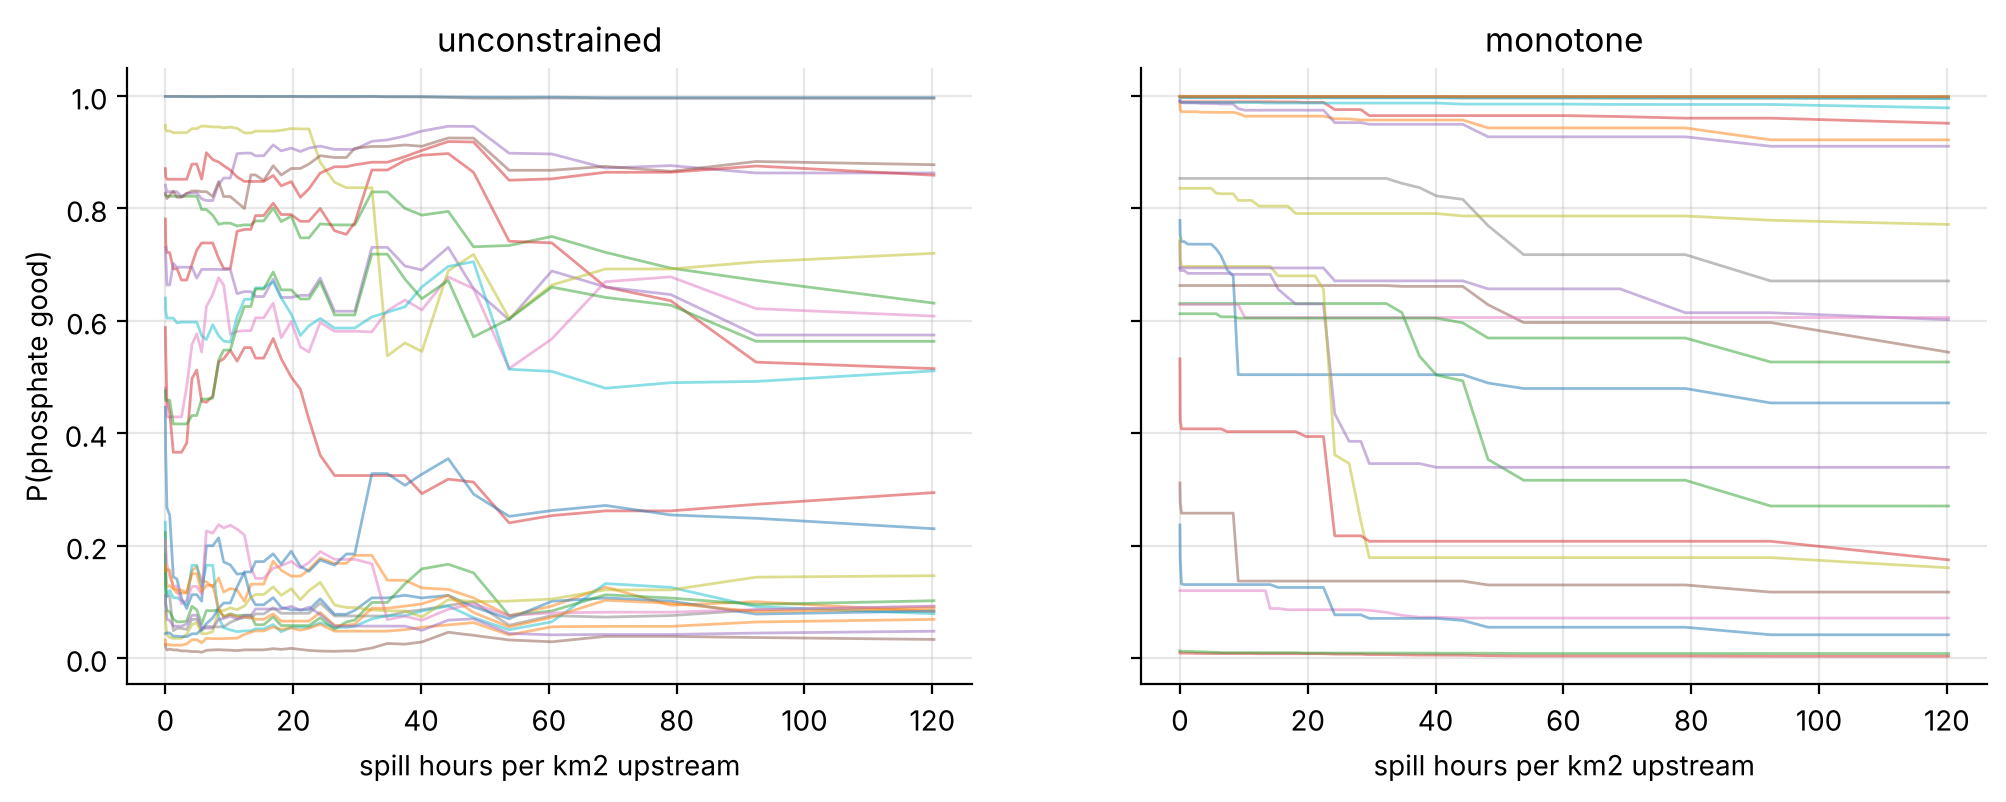

In [2]:
import lightgbm as lgb
mono = [-1, -1, -1, 0, 0, 0, 0, -1]          # sewage flow, spills, urban, private sewage: never helpful
print(dict(zip(F, mono)))
free = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=10, verbose=-1).fit(X, y)
cons = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=10, verbose=-1,
                          monotone_constraints=mono, monotone_constraints_method="advanced").fit(X, y)
j = F.index("up_spill_hours_per_km2"); grid = np.quantile(X[:, j], np.linspace(0, 0.98, 60))
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
rng = np.random.default_rng(0)
for a_, m, title in [(ax[0], free, "unconstrained"), (ax[1], cons, "monotone")]:
    for i in rng.choice(len(y), 25, replace=False):           # ICE curves: one river at a time
        Z = np.repeat(X[[i]], len(grid), 0); Z[:, j] = grid
        a_.plot(grid, m.predict_proba(Z)[:, 1], alpha=0.5, lw=1)
    a_.set_title(title); a_.set_xlabel("spill hours per km2 upstream")
ax[0].set_ylabel("P(phosphate good)"); plt.show()

In [3]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups))
for lab, kw in [("unconstrained", {}), ("monotone", dict(monotone_constraints=mono, monotone_constraints_method="advanced"))]:
    o = np.zeros(len(y))
    for a, b in folds:
        o[b] = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30, verbose=-1,
                                  **kw).fit(X[a], y[a]).predict_proba(X[b])[:, 1]
    print(f"{lab:14s} spatial-CV AUC {roc_auc_score(y, o):.3f}")

unconstrained  spatial-CV AUC 0.808


monotone       spatial-CV AUC 0.810


The unconstrained curves wiggle up and down; the constrained ones only fall. Accuracy is unchanged
(0.810 constrained vs 0.808 free): the wiggles were noise.

## Calibration

A probability is calibrated if, among rivers given 30%, about 30% are good. Trees' raw scores often are not:
random forests pull towards 0.5 (averaging), and boosting with log loss is usually close but can be
over-confident when overfitted.

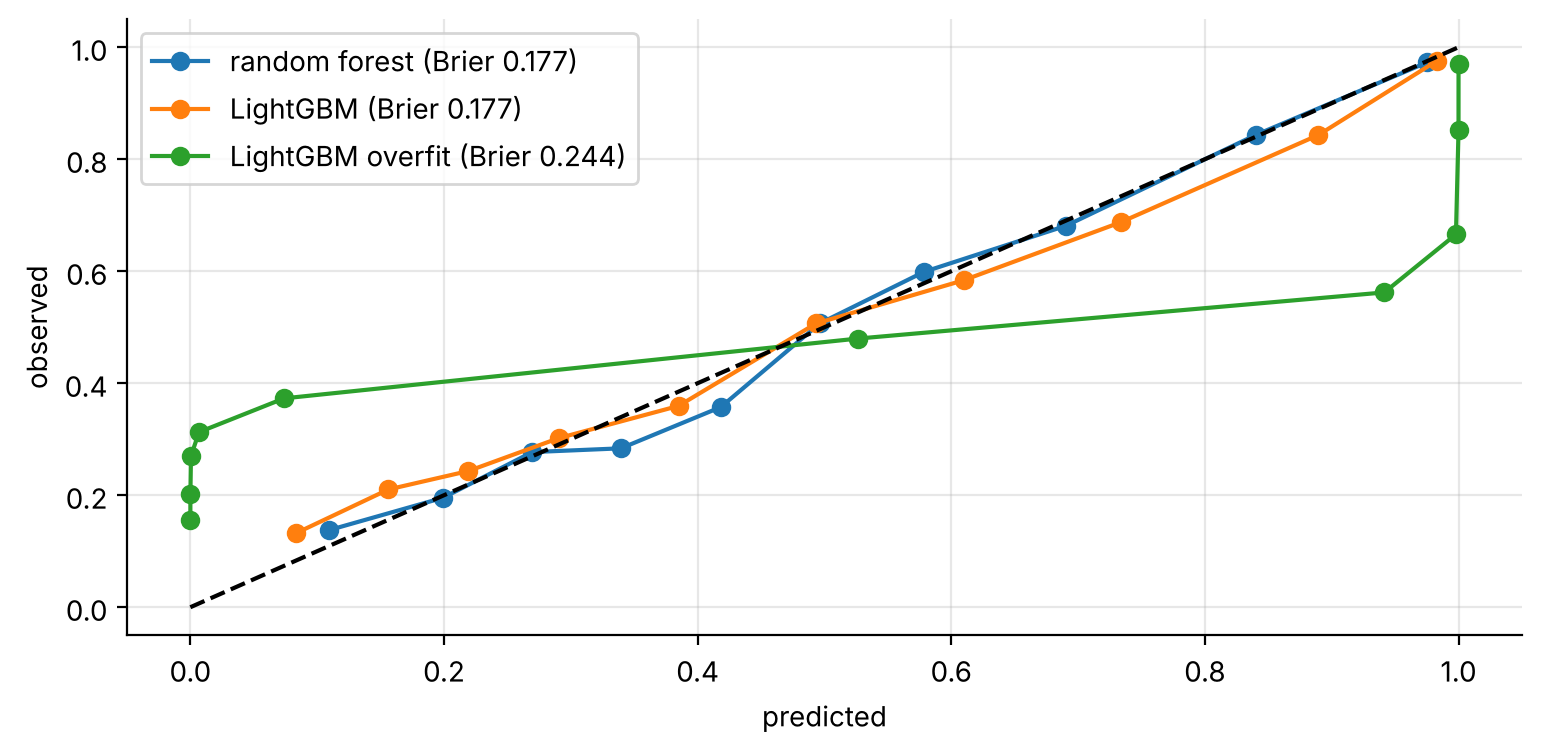

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
oofs = {}
for lab, mk in [("random forest", lambda: RandomForestClassifier(300, min_samples_leaf=1, n_jobs=-1, random_state=0)),
                ("LightGBM", lambda: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, verbose=-1)),
                ("LightGBM overfit", lambda: lgb.LGBMClassifier(n_estimators=1500, learning_rate=0.1, num_leaves=63,
                                                                min_child_samples=2, verbose=-1))]:
    o = np.zeros(len(y))
    for a, b in folds: o[b] = mk().fit(X[a], y[a]).predict_proba(X[b])[:, 1]
    oofs[lab] = o
    fy, fx = calibration_curve(y, o, n_bins=10, strategy="quantile")
    plt.plot(fx, fy, marker="o", label=f"{lab} (Brier {brier_score_loss(y, o):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("predicted"); plt.ylabel("observed"); plt.legend(); plt.show()

## Fixing calibration: isotonic regression on out-of-fold scores

The deliberately overfitted booster is badly over-confident. Isotonic regression learns a monotone map
from score to observed frequency, fitted on other folds' out-of-fold scores.

In [5]:
from sklearn.isotonic import IsotonicRegression
o = oofs["LightGBM overfit"]; fixed = np.zeros(len(y))
for a, b in folds:                                    # fit the calibrator on other folds' OOF scores
    fixed[b] = IsotonicRegression(out_of_bounds="clip").fit(o[a], y[a]).predict(o[b])
print(f"Brier before {brier_score_loss(y, o):.3f}  after {brier_score_loss(y, fixed):.3f}")

Brier before 0.244  after 0.181
